#### Map ACTib from JSON

In [2]:
import json
import os
import cv2
import json
import shutil
import pyewts
import random
import numpy as np
import matplotlib.pyplot as plt

from tqdm import tqdm
from glob import glob
from pathlib import Path
from evaluate import load
from natsort import natsorted
from Modules import PatchedLineDetection, PatchedPerigLayoutDetection, OCRInference
from IPython.display import Image as ShowImage
from Utils import create_dir, get_json, get_line_images_from_line_data, rotate_from_angle, get_random_color

d:\Github\OCR-Inference\venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
def show_image(image: np.array, cmap: str = "") -> None:
    plt.figure(figsize=(24, 13))
    #plt.axis("off")
    
    if cmap != "":
        plt.imshow(image, cmap=cmap)
    else:
        plt.imshow(image)

In [4]:
converter = pyewts.pyewts()
cer_scorer = load("cer")

layout_config = "Models\LayoutModels\LA_v2_2024-1-22_6-36\model_config.json"
layout_inference = PatchedPerigLayoutDetection(layout_config)

d:\Github\OCR-Inference\venv\lib\site-packages\onnxruntime\capi\onnxruntime_inference_collection.py:69: UserWarning: Specified provider 'CUDAExecutionProvider' is not in available provider names.Available providers: 'AzureExecutionProvider, CPUExecutionProvider'
  warnings.warn(


In [5]:
test_vol = "D:\Github\OCR-Inference\Data\W23703\I1530"
images = natsorted(glob(f"{test_vol}/*.jpg"))

etext_file = "Data/W23703/eText/23703-1528.json"
etext_pages = get_json(etext_file)
etext_pages = list(etext_pages.values())
etext_pages = [x for x in etext_pages if x != [""]]

print(f"Images: {len(images)}, Pages: {len(etext_pages)}")

Images: 652, Pages: 652


རྩངས་པ་དང་ནི།མིག་སྨན་རྩ།༧།ཀྲྀ་ཀ་ལཱ་ས་སོག་ལེ་ཅན།། ཉིན་ས་བ་དང་རལ་གྲི་ཅན།། ཙེ་དཱ་ར་དང་།རྩྭའི་ད་བྱིད།། རྩངས་ཕྲན་དང་ནི་ཁྱིམ་གྱི་རྩངས།། མཐུ་བོ་དང་ནི་ཁྱིམ་ལྡན་དང་།། མདུང་ཅན་ལྟས་ཤེས་ཙ་ཊཾ་གི།གཤོལ་ལྡན་དང་ནི།བཀྲ་བ་དང་།། རྒྱལ་
བ་བཞོན་པ་ཆེན་པོའོ།༤།བྱེད་པ།ཀ་རཱ།ཊི་ཀཱ་དང་།། རྣ་ཆུ།ཀ་ཤ་ཏ་པ་ཊི།། འབུ་དང་།གྲོགས་སྦུར།ནཱི་ལཾ་གུ།། རྐང་བརྒྱད་པ་དང་།འབུ་ཕྲན་ནོ།། ལྟེ་བ་བལ་ཅན་སྤྲེའུ་འདྲ་དང་།། ཐུར་མ་ཅན་དང་།དྲ་བ་ཅན།། སྡོམ་དང་།ཐགས་མཁན་ཞེས་
བྱའོ།། འདིས་བཅིངས།རྒྱ་དང་འདྲ་བའོ།། རྟ་ཤིག་པ་དང་སྡིག་པའོ།། འབུ་ཕྲན་དང་ནི་སྦུར་བུ་དང་།། འབུ་ནར་དང་ནི་མཇུག་མ་ཅན།། བ་མི།ཟ་བྱེད།ཀ་བ་ཊི།། ཉེ་ལུས་ཉེ་བར་ཕྱོགས་པ་དང་།། སྐྲ་འདྲ།ཉེ་བའི་ལྕེ་ཅན་ནོ།། གྲོག་མ་དང་ནི།སྲིན་
ཕྲན་དང་།། གཤིན་རྗེའི་བུ་དང་།གྷུ་རྒྱུ་ར།། དར་གྱི་སྲིན་འབུ།། སྐུད་པའི་བུ།རྩ་འབུ།ཤིང་ཟན་ཡི་གེ་པ།། སྟེང་གི་ཤ་དང་མ་ཀུ་ཤ།མདུད་ཅན་སྐྱེ་བ་ཕྲ་མོའོ།། ཕྱུགས་ལ་སོགས་པའི་རབ་ཏུ་བྱེད་པའོ།། །། མཁའ་འགྲོ་ཡན་ལག་དྲུག་པ་
དང་།། མཁའ་ལ་འགྲོ་དང་།མཁའ་ལ་འཕུར།། པ་ཏ་འགའ་དང་།འདབ་གཤོག་ཅན།། འདབ་སྐྱོབ་དང་ནི།འདབ་མས་སྐྱོབ།། བྱ་དང་།སྒྲོ་ལྡན།ཤ་ཀུནྡ།། ཤ་ཀུནྟ་ཡ་བི་ཀ་རེ།། བདྐི་ར་དང་།ནམ་མཁའི་རྟ།། མཁར་ཉལ།ཚོང་ལས་བྱུང་བ་དང་

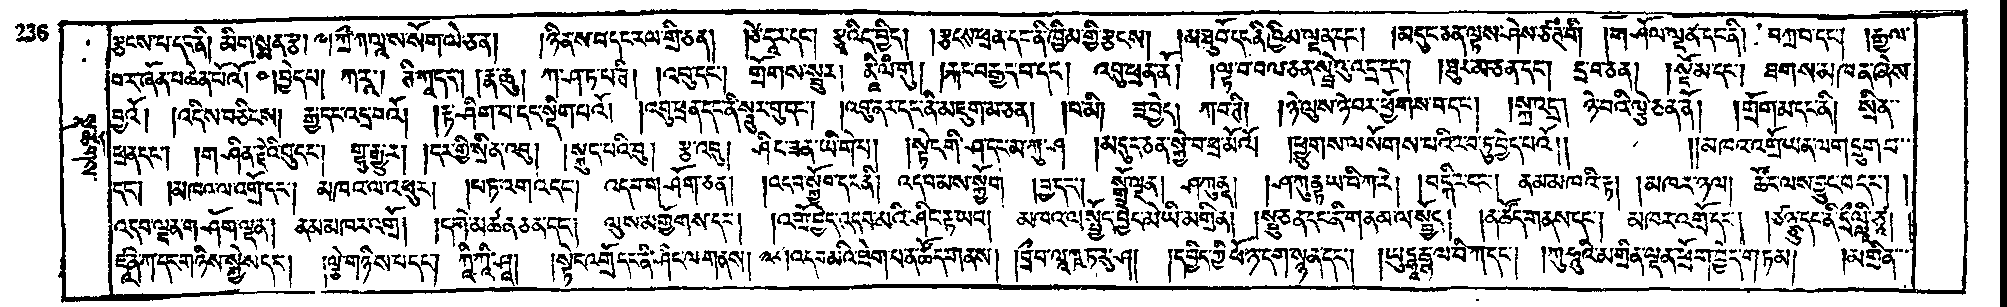

In [15]:
img_idx = 234

for line in etext_pages[img_idx]:
    print(line)

ShowImage(images[img_idx])

In [21]:
# layout_inference
try:
  image_name = os.path.basename(images[img_idx]).split(".")[0]
  _img = cv2.imread(images[img_idx])

  print(_img.shape)

except FileExistsError as e:
    print.error(f"Cant read file at provided location: {images[img_idx]}, {e}")

# layout_inference
layout_data, preview_img = layout_inference.predict(_img)
#print(preview_img.shape)
#show_image(preview_img)

(307, 2007, 3)


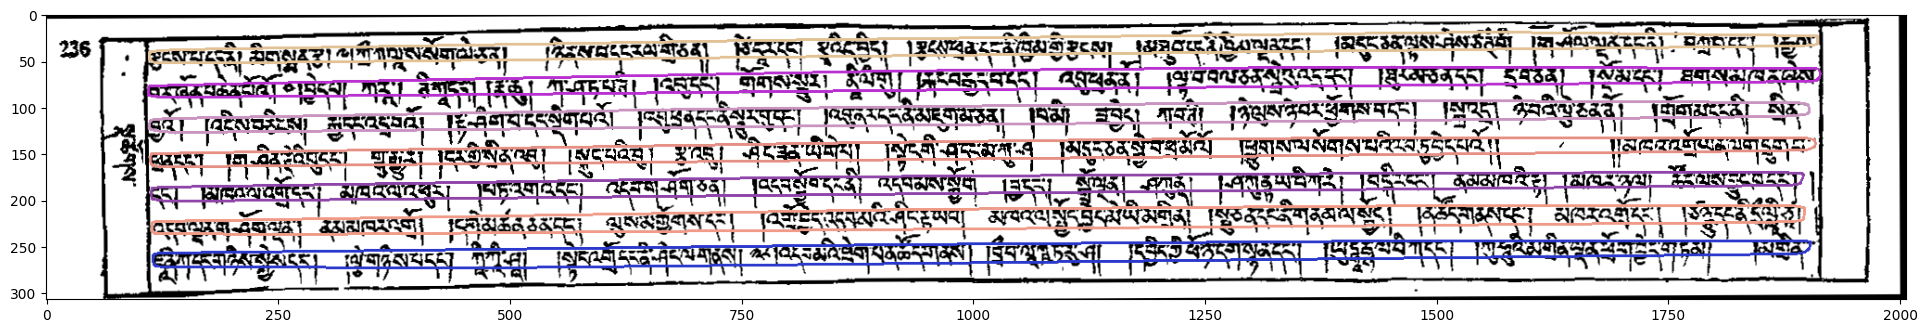

In [27]:
sorted_layout_data = layout_inference.sort_lines(layout_data, threshold=20, calculate=False)
r_img = rotate_from_angle(_img, layout_data.rotation)
prev_img = r_img.copy()
color = get_random_color()

for line_data in layout_data.lines:
    color = get_random_color()
    cv2.drawContours(prev_img,[line_data.contour],contourIdx=-1,color=color,thickness=2)

show_image(prev_img) 

In [42]:
layout_line_images = get_line_images_from_line_data(r_img, sorted_layout_data.lines, dilate_kernel=24, dilate_iterations=16, calculate_iterations=False)
#rev_images = list(reversed(layout_line_images))

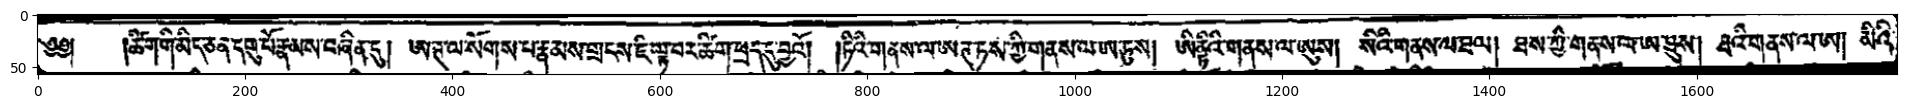

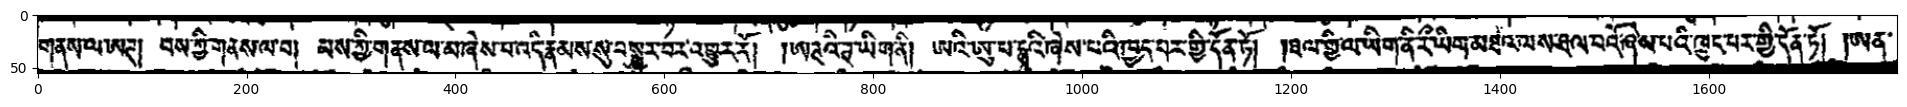

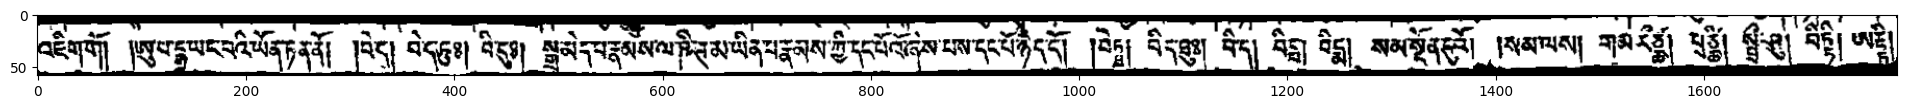

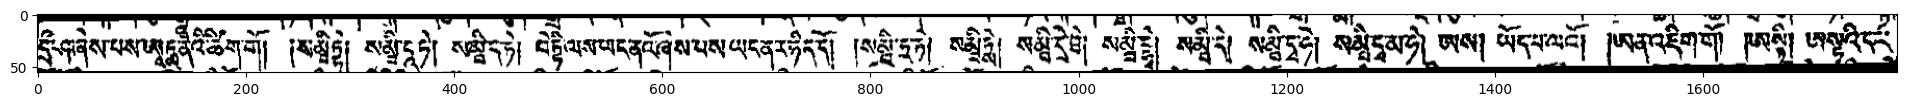

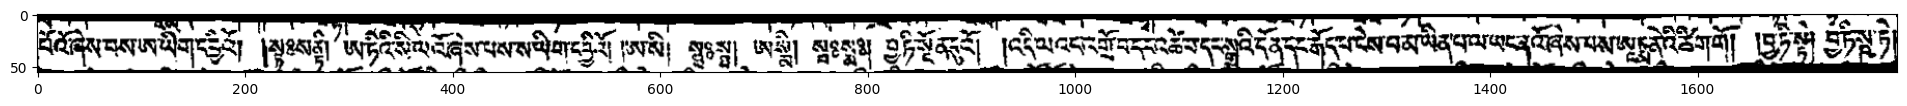

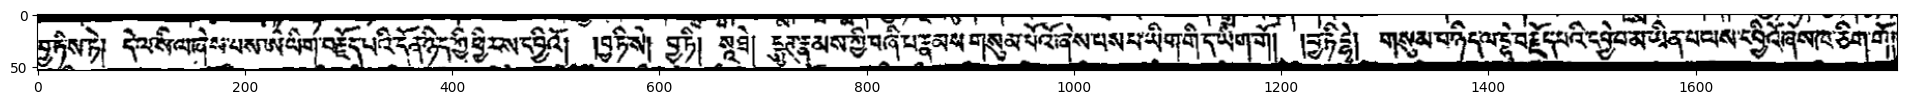

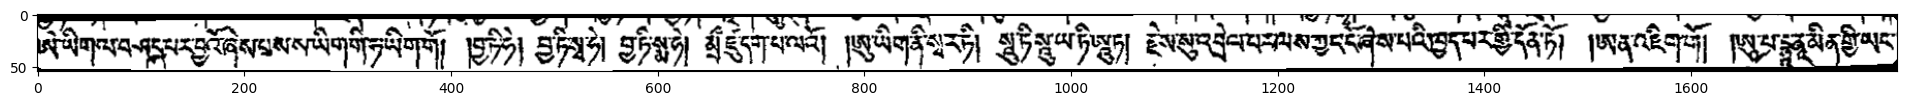

In [43]:
for idx, img in enumerate(layout_line_images):
    show_image(layout_line_images[idx])

In [44]:
test_line_out = "test_line.jpg"
cv2.imwrite(test_line_out, layout_line_images[0])

True

### run the volume

In [29]:
from Exporter import PageXMLExporter

In [31]:
test_vol = "D:\Github\OCR-Inference\Data\W23703\I1530"
images = natsorted(glob(f"{test_vol}/*.jpg"))

etext_file = "Data/W23703/eText/23703-1528.json"
etext_pages = get_json(etext_file)
etext_pages = list(etext_pages.values())
etext_pages = [x for x in etext_pages if x != [""]]

print(f"Images: {len(images)}, Pages: {len(etext_pages)}")


out_dir = os.path.join(test_vol, "xml")
xml_out = os.path.join(out_dir, "page")

xml_exporter = PageXMLExporter(xml_out)

create_dir(out_dir)
create_dir(xml_out)

Images: 652, Pages: 652


In [47]:
dataset_out = os.path.join(test_vol, "DatasetJanuary2024")
dataset_lines_out = os.path.join(dataset_out, "lines")
dataset_labels_out = os.path.join(dataset_out, "transcriptions")
create_dir(dataset_out)
create_dir(dataset_lines_out)
create_dir(dataset_labels_out)

out_dir = os.path.join(dataset_out, "xml")
xml_out = os.path.join(out_dir, "page")

xml_exporter = PageXMLExporter(xml_out)

create_dir(out_dir)
create_dir(xml_out)

In [48]:
mismatch_pages = []

for idx, (image, page_text) in tqdm(enumerate(zip(images, etext_pages)), total=len(images)):
    # layout_inference
    try:
        image_name = os.path.basename(image).split(".")[0]
        _img = cv2.imread(image)

    except FileExistsError as e:
        print.error(f"Cant read file at provided location: {image}, {e}")
        continue
    
    # layout_inference
    layout_data, _ = layout_inference.predict(_img)
    sorted_layout_data = layout_inference.sort_lines(layout_data, threshold=20, calculate=False)
    r_img = rotate_from_angle(_img, layout_data.rotation)
    layout_line_images = get_line_images_from_line_data(r_img, sorted_layout_data.lines, dilate_kernel=24, dilate_iterations=16, calculate_iterations=False)

    if len(layout_line_images) == len(page_text):
        #img_out = f"{out_dir}/{image_name}.jpg"
        #cv2.imwrite(img_out, r_img)
        #xml_exporter.export(r_img, image_name, )

        for s_idx, (l_img, l_lbl) in enumerate(zip(layout_line_images, page_text)):
            
            img_out = f"{out_dir}/{image_name}.jpg"
            cv2.imwrite(img_out, r_img)
            xml_exporter.export(r_img, image_name, sorted_layout_data, page_text)
            
            """
            direct line-txt output
            
            img_out = f"{dataset_lines_out}/{image_name}_{s_idx}.jpg"
            lbl_out = f"{dataset_labels_out}/{image_name}_{s_idx}.txt"

            cv2.imwrite(img_out, layout_line_images[s_idx])

            with open(lbl_out, "w", encoding="utf-8") as f:
                f.write(page_text[s_idx])
            """
    else:
        #print("page-line mismatch")
        mismatch_pages.append(image)


print(f"Mismatched pages: {len(mismatch_pages)}")

mismatch_pages_out = f"{dataset_out}/page_mismatches.txt"

with open(mismatch_pages_out, "w", encoding="utf-8") as f:
    for p in mismatch_pages:
        f.write(f"{p}\n")

100%|██████████| 652/652 [24:18<00:00,  2.24s/it]

Mismatched pages: 61


In [46]:
mismatch_pages_out = f"{dataset_out}/page_mismatches.txt"

with open(mismatch_pages_out, "w", encoding="utf-8") as f:
    for p in mismatch_pages:
        f.write(f"{p}\n")